
**JEPA vs. AR for sequence modeling.**
<br>Task: voice transcription.
<br>**Research project description:** Exploring the mathematical foundations of implementing JEPA for sequential and voice transcription tasks. The project investigates how
predicting in representation space via contrastive loss handles large vocabularies and fine-grained noise compared to traditional
Autoregressive models. Experimental work will evaluate optimization techniques such as Bayesian initialization, quantization, and
activation function approximations with the ultimate goal of producing a comprehensive literature review and an initial research paper draft

In [ ]:
import os
from huggingface_hub import login
hf_token = os.getenv("HF_TOKEN")
if hf_token is None:
    raise ValueError("HF_TOKEN environment variable is not set.")
login(token=hf_token)

**LibriSpeech dataset.**
<br>LibriSpeech is a corpus of approximately 1000 hours of 16kHz read English speech. The data is derived from read audiobooks from the LibriVox project, and has been carefully segmented and aligned.

In [2]:
# Dataset
from datasets import load_dataset

ds = load_dataset("openslr/librispeech_asr", "clean")
# keys: ['test', 'train.100', 'train.360', 'validation']

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/47 [00:00<?, ?it/s]

### 1. Whisper Feature Extractor

We use Whisper to extract mel-spectrograms from raw audio LibriSpeech dataset. The audio processor converts raw waveforms into mel-scale spectrograms of fixed dimensions.

Mel-spectrogram dimensions:
- Frequency bins (mel-scale): $F = 128$
- Time frames: $T = 3000$
- Output shape: $\mathbf{X} \in \mathbb{R}^{B \times 1 \times F \times T} = \mathbb{R}^{B \times 1 \times 128 \times 3000}$

where $B$ is the batch size, and the factor of 1 represents a single audio channel.

These mel-spectrograms serve as input to both the Context Encoder and Target Encoder in the JEPA framework for audio representation learning.

In [3]:
import torch
from transformers import AutoProcessor, WhisperModel


# Whisper
model_name = "openai/whisper-large-v3-turbo"
whisper_model = WhisperModel.from_pretrained(model_name, device_map="auto", attn_implementation="sdpa")
processor = AutoProcessor.from_pretrained(model_name)

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

### 2. Dataset

In [4]:
from torch.utils.data import Dataset, DataLoader

class AbstractDataset(Dataset):
    def __init__(self, ds_split, processor):
        self.ds = ds_split
        self.processor = processor

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        sample = self.ds[idx]
        audio = sample["audio"]
        inputs = self.processor(
            audio["array"], 
            sampling_rate=audio["sampling_rate"], 
            return_tensors="pt"
        )
        input_features = inputs.input_features
        label_out = self.processor(text=sample["text"])
        label = torch.tensor(label_out["input_ids"])
        
        return {
            "input_features": input_features,
            "label": label,
            "speaker_id": sample["speaker_id"],
            "chapter_id": sample["chapter_id"],
        }
    
# Development
ds_train_100 = AbstractDataset(ds["train.100"].select(range(1000)), processor)
ds_val = AbstractDataset(ds["validation"].select(range(200)), processor)
ds_test = AbstractDataset(ds["test"].select(range(200)), processor)

# Production
# ds_train_100 = AbstractDataset(ds["train.100"], processor)
# ds_val = AbstractDataset(ds["validation"], processor)
# ds_test = AbstractDataset(ds["test"], processor)

### 3. Positional Encoding

2d sinusoidal positional encoding is used.

In [5]:
# 2d Sin-Cos positional encoding
def get_2d_sincos_pos_enc(num_patches_f, num_patches_t, embed_dim, n=10000):
    half_dim = embed_dim // 2 # 386//2 = 193
    
    pos_f = torch.arange(num_patches_f, dtype=torch.float32).unsqueeze(1) # 8 x 1
    pos_t = torch.arange(num_patches_t, dtype=torch.float32).unsqueeze(1) # 187 x 1
    dim_t = torch.arange(half_dim // 2, dtype=torch.float32) # 193//2 = 96
    omega = 1.0 / (n ** (2 * dim_t / half_dim))

    # Frequency encoding
    out_f = torch.zeros((num_patches_f, half_dim)) # 8 x 192
    out_f[:, 0::2] = torch.sin(pos_f * omega)
    out_f[:, 1::2] = torch.cos(pos_f * omega)
    
    # Time encoding
    out_t = torch.zeros((num_patches_t, half_dim)) # 187 x 192
    out_t[:, 0::2] = torch.sin(pos_t * omega)
    out_t[:, 1::2] = torch.cos(pos_t * omega)
    
    emb_f = out_f.unsqueeze(1).repeat(1, num_patches_t, 1) # 8 x 1 x 192 -> 8 x 187 x 193
    emb_t = out_t.unsqueeze(0).repeat(num_patches_f, 1, 1) # 1 x 187 x 192 -> 8 x 187 x 193
    pos_2d = torch.cat([emb_f, emb_t], dim=-1)  # 8 x 187 x 386
    pos_2d = pos_2d.view(-1, embed_dim) # (F * T) x D
    pos_2d = pos_2d.to(dtype=whisper_model.dtype, device=whisper_model.device)
    
    return pos_2d 

### 4. Masking Strategies

**References:**
- https://arxiv.org/pdf/2207.06405 (Masked Autoencoders that Listen)
- https://arxiv.org/pdf/2211.09944 (MelHuBERT: A Simplified HuBERT on Mel Spectrograms)

**Masking Types** (`mask_type` parameter):
- **Random (unstructured)**: Randomly masks any mel-spectrogram patches <- default choice
- **Time**: Masks contiguous time frames
- **Frequency**: Masks contiguous frequency
- **Time-Frequency (structured)**: Simultaneously masks both time and frequency dimensions

**Masking Ratio Strategies** (`mask_selection` parameter):
- **Static**: Fixed masking ratio throughout training
- **Uniform**: Randomly samples ratio from U(0.4, 0.6) per batch
- **Normal**: Samples from Gaussian distribution N(mask_ratio, 0.1), clipped to [0.15, 1.0]
- **Poisson**: Samples from Poisson distribution for stochastic masking intensity

In [6]:
def get_mask_indices_2d(
        mel_tensor,
        mask_type="random",
        mask_ratio=0.6,
        mask_selection="static",
        patch_h=16,
        patch_w=16,
    ):

    if mask_selection == "static":
        p = mask_ratio
    elif mask_selection == "uniform":
        p = torch.empty(1).uniform_(0.4, mask_ratio).item()
    elif mask_selection == "normal":
        p = torch.empty(1).normal_(mean=mask_ratio, std=0.1).clamp_(0.15, 1.0).item()
    elif mask_selection == "poisson":
        p = torch.poisson(torch.tensor([mask_ratio * 10.0])).item() / 10.0
        p = min(max(p, 0.0), 1.0)
    
    B, C, F, T = mel_tensor.shape # B x Channel(=1) x Freq dim x Time dim (128 x 3000)
    num_patches_f = F // patch_h # 128//16 = 8
    num_patches_t = T // patch_w # 3000//16 = 187
    num_total_patches = num_patches_f * num_patches_t # 8*187 = 1496
    
    if mask_type == "random":
        num_mask = int(p * num_total_patches)
        mask_indices = torch.rand(B, num_total_patches, device=mel_tensor.device).argsort(dim=1)[:, :num_mask]
        
    elif mask_type == "time":
        num_mask_t = int(p * num_patches_t)
        t_indices = torch.rand(B, num_patches_t, device=mel_tensor.device).argsort(dim=1)[:, :num_mask_t]
        grid_mask = torch.zeros((B, num_patches_f, num_patches_t), dtype=torch.bool, device=mel_tensor.device)
        batch_idx = torch.arange(B, device=mel_tensor.device)[:, None]
        grid_mask[batch_idx, :, t_indices] = True
        mask_indices = grid_mask.view(B, -1).nonzero()[:, 1].view(B, -1)
        
    elif mask_type == "freq":
        num_mask_f = int(p * num_patches_f)
        f_indices = torch.rand(B, num_patches_f, device=mel_tensor.device).argsort(dim=1)[:, :num_mask_f]
        grid_mask = torch.zeros((B, num_patches_f, num_patches_t), dtype=torch.bool, device=mel_tensor.device)
        batch_idx = torch.arange(B, device=mel_tensor.device)[:, None]
        grid_mask[batch_idx, f_indices, :] = True
        mask_indices = grid_mask.view(B, -1).nonzero()[:, 1].view(B, -1)
        
    elif mask_type == "time_freq":
        x = 1.0 - torch.sqrt(torch.tensor(max(0.0, 1.0 - p))).item()
        num_t = int(x * num_patches_t)
        num_f = int(x * num_patches_f)
        t_indices = torch.rand(B, num_patches_t, device=mel_tensor.device).argsort(dim=1)[:, :num_t]
        f_indices = torch.rand(B, num_patches_f, device=mel_tensor.device).argsort(dim=1)[:, :num_f]
        grid_mask = torch.zeros((B, num_patches_f, num_patches_t), dtype=torch.bool, device=mel_tensor.device)
        batch_idx = torch.arange(B, device=mel_tensor.device)[:, None]
        grid_mask[batch_idx, :, t_indices] = True
        grid_mask[batch_idx, f_indices, :] = True
        mask_indices = grid_mask.view(B, -1).nonzero()[:, 1].view(B, -1)

    return mask_indices # B x (D*mask_ratio)

### 5. Encoders: Context and Target

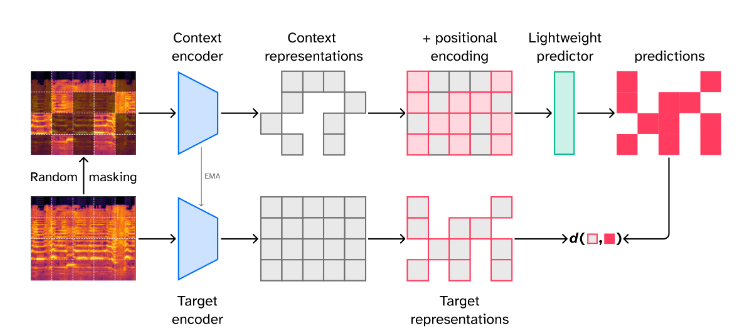

The JEPA architecture comprises two main encoder components that work in tandem for audio representation learning:

**Context Encoder:**
- Processes masked mel-spectrograms
- Parameters updated via standard gradient descent
- Consists of Patch Embedding layer followed by ViT-Base
- Outputs unmasked patch representations

**Target Encoder:**
- Processes full, unmasked mel-spectrograms
- Parameters updated via Exponential Moving Average (EMA) with momentum = 0.996
- Identical architecture to Context Encoder but with disabled gradients
- Provides stable target representations for contrastive learning

#### 5.1. Encoder Architecture Components.

5.1.1. Patch Embedding:
* Source paper: https://arxiv.org/pdf/2507.02915#page=3.03 (Audio-JEPA: Joint-Embedding Predictive Architecture for Audio Representation Learning)
* Implementation is taken from: https://github.com/LudovicTuncay/Audio-JEPA/blob/main/src/models/components/vision_transformer.py#L228
* Mel-spectrograms are patchified before being passed to the Context Encoder and Target Encoder.
* A 2D convolutional block is applied with a kernel size of $16 \times 16$ (the patch size).
* Input: $\text{In\_Chan} \times F \times T = 1 \times 128 \times 3000$
* Stride: $16 \times 16$ (no overlapping patches)
* Output (transformed): $B \times (128//16 \times 3000//16) \times 768 = B \times 1496 \times 768$
* Each patch is projected into a 768-dimensional hidden representation.
* 2D sinusoidal positional encodings are added to retain frequency and temporal location information.

In [7]:
from torch import nn

class PatchEmbed(nn.Module):
    def __init__(self, input_size=(128, 3000), patch_size=(16, 16), in_chans=1, embed_dim=768):
        super().__init__()
        mel_h, mel_width = input_size
        patch_height, patch_width = patch_size
        self.embed_dim = embed_dim
        self.input_size = input_size
        self.patch_size = patch_size
        self.num_patches_h = mel_h // patch_height
        self.num_patches_w = mel_width // patch_width
        self.num_patches = self.num_patches_h * self.num_patches_w

        self.proj = nn.Conv2d(in_channels=in_chans, out_channels=embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x): # B x 1 x 128 x 3000
        h = self.proj(x) # B x 768 x (128//16=8) x (3000//16=187)
        h = h.flatten(2).transpose(1, 2) # B x 1496 x 768
        h = h + get_2d_sincos_pos_enc(128//16, 3000//16, self.embed_dim).to(x.device)  # B x 1496 x 768
        return h

5.1.2. ViT-Base encoder.

The patchified mel-spectrograms are passed to a ViT-Base encoder following the Vision Transformer architecture introduced in the original ViT paper: https://arxiv.org/pdf/2010.11929

Each 16 × 16 mel-spectrogram patch is projected into a 768-dimensional token embedding via `PatchEmbed`, and 2D sinusoidal positional encodings are added to preserve both frequency and temporal positions. The resulting sequence of patch tokens is then processed by a standard Transformer encoder with:

- 12 layers
- 12 attention heads
- hidden dimension = 768
- MLP expansion factor = 4

In [8]:
class ViT_Base(nn.Module):
    def __init__(self, embed_dim=768, depth=12, num_heads=12, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim*mlp_ratio),
            dropout=dropout,
            activation="gelu",
            batch_first=True,
        )
        self.blocks = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)
        
    def forward(self, x, ):
        # Input: B x L [unmasked/full] x D
        x = self.blocks(x) 
        x = self.norm(x)
        return x # B x L [unmasked/full] x D

### 5.2. Audio Encoder Implementation

The audio encoder combines three components:

- Patch embedding: converts a mel-spectrogram into a sequence of non-overlapping 16 × 16 patches.
- ViT encoder: applies a standard Transformer encoder over the patch sequence.
- Layer normalization.

Depending on the role:

- Context Encoder:
    - receives a masked mel-spectrogram
    - updates its parameters via gradient descent
    - produces unmasked patch representations that are used by the predictor network
    - output shape: $\mathbf{X_{ctx}} \in \mathbb{R}^{B \times L_{unmasked} \times D} = \mathbb{R}^{B \times L_{unmasked} \times 768}$

- Target Encoder:
    - receives the full, unmasked mel-spectrogram
    - retains an exponential moving average (EMA) copy of the context encoder
    - is kept frozen during backpropagation
    - output shape: $\mathbf{X_{tgt}} \in \mathbb{R}^{B \times L_{masked} \times D} = \mathbb{R}^{B \times L_{masked} \times 768}$

where $L_{masked/unmasked}$ is the number of masked/unmasked patches (determined by the masking ratio), $L = 1496$ is the total number of patches, and $D = 768$ is the embedding dimension.


In [ ]:
class AudioEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embed = PatchEmbed()
        self.vit_encoder = ViT_Base()
        self.norm_layer = nn.LayerNorm(768)

    def forward(self, x, mask_indices=None):
        """
        mask_indices: Only passed for Target Encoder to extract targets.
        """
        x_embed = self.patch_embed(x) # B x L x D
        B, L, D = x_embed.shape
        print("audio_encoder x shape:", B,L,D)

        # Mask input for Context Encoder
        if mask_indices is None:
            mask_indices = get_mask_indices_2d(x, mask_ratio=0.6) # B x L_masked ~ U(0.4,0.6)
            print("audio_encoder mask_indices", mask_indices.shape)
            bool_mask = torch.zeros((B, L), dtype=torch.bool, device=x_embed.device)
            bool_mask.scatter_(dim=1, index=mask_indices, value=True)

            # Only process visible parts
            L_unmasked = L - mask_indices.shape[1]
            x_unmasked = x_embed[~bool_mask].view(B, L_unmasked, D) # B x L_unmasked x D
            x_out = self.vit_encoder(x_unmasked)
            
            return x_out, mask_indices, bool_mask # context    
      
        # Preserve the full input for Target Encoder
        x_out = self.vit_encoder(x_embed)
        x_out = self.norm_layer(x_out)

        # Get targets only
        batch_ids = torch.arange(B, device=x.device).unsqueeze(1)
        x_out = x_out[batch_ids, mask_indices, :]

        return x_out # targets

### 6. Predictor

The predictor network learns to reconstruct the target representations for the masked audio patches from the visible patch representations produced by the Context Encoder.

Architecture:
- Linear projection from `768 -> 384`
- 2D sinusoidal positional encoding for both visible and masked patch positions
- Lightweight Transformer encoder with:
    - `depth = 6`
    - `num_heads = 12`
    - MLP expansion factor = 4
- Layer normalization after the Transformer blocks
- Output projection from `384 -> 768`
- Learnable mask tokens initialized with Gaussian noise (`std = 0.02`)

Forward path:
- Input context: $\mathbf{X}_{ctx} \in \mathbb{R}^{B \times L_{\mathrm{unmasked}} \times 768}$

- Projected context: $\mathbf{X}_{ctx}^{\prime} \in \mathbb{R}^{B \times L_{\mathrm{unmasked}} \times 384}$

- Predictor output: $\mathbf{\hat{Y}}_{ctx} \in \mathbb{R}^{B \times L_{\mathrm{masked}} \times 768}$

The predictor takes the unmasked context tokens, adds positional information, inserts learned mask tokens at the masked positions, and refines the combined sequence through ViT.

The final predictions are then compared against the target encoder outputs using MSE loss:
$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} \left( \mathbf{X}_{ctx, i}^{\prime} - \mathbf{\hat{Y}}_{ctx, i} \right)^2$$

In [10]:
class Predictor(nn.Module):
    def __init__(self, encoder_dim=768, embed_dim=384, depth=6, num_heads=12, mlp_ratio=4.0, dropout=0.0):
        super().__init__()

        self._pos_enc_tensor = get_2d_sincos_pos_enc(
            128//16, 3000//16, embed_dim=embed_dim
        ) # (8*187=1496) x 384, L x D 
        self._mask_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout,
            activation="gelu",
            batch_first=True,
        )
        self.ctx_proj = nn.Linear(encoder_dim, embed_dim)
        self.blocks = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)
        self.proj = nn.Linear(embed_dim, encoder_dim)

        # Gaussian init
        nn.init.normal_(self._mask_token, std=0.02)

    def forward(self, x_ctx, mask_indices, bool_mask):
        """
        x_ctx: B x L_unmasked x 768
        mask_indices: B x L_masked
        bool_mask: B x L
        """
        B = x_ctx.shape[0]
        x_ctx = self.ctx_proj(x_ctx) # B x L_unmasked x 384
        
        ctx_indices = (~bool_mask).nonzero(as_tuple=False)[:, 1].view(B, -1) # B x L_unmasked

        ctx_pos_embed = self._pos_enc_tensor[ctx_indices] # B x L_unmasked x D
        target_pos_embed = self._pos_enc_tensor[mask_indices] # B x L_masked x D
        x_ctx = x_ctx + ctx_pos_embed # B x L_unmasked x D

        # Target tokens
        L_masked = mask_indices.shape[1]
        mask_tokens = self._mask_token.expand(B, L_masked, -1) # B x L_masked x D
        mask_tokens = mask_tokens + target_pos_embed # B x L_masked x D
        
        x = torch.cat([x_ctx, mask_tokens], dim=1) # B x L x D
        x = self.blocks(x)
        x = self.norm(x)
        x = self.proj(x) # B x 1496 x 384 -> B x 1496 x 768
        preds = x[:, -L_masked:, :] # B x L_masked x D

        return preds

### 7. Building JEPA components and Setup DataLoaders.

In [11]:
import copy

# JEPA model components

ctx_encoder = AudioEncoder().to(whisper_model.device)
predictor = Predictor().to(whisper_model.device)

# Target Encoder's architecture is the same as Context Encoder.
# Gradients are disabled, parameters are updated via EMA.
target_encoder = copy.deepcopy(ctx_encoder)
for param in target_encoder.parameters():
    param.requires_grad = False

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence
from tqdm import tqdm
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR

# Match input and label size for the dataset
def whisper_collate_fn(batch):
    input_features = [item["input_features"].squeeze(0) for item in batch]
    input_features = torch.stack(input_features) # B x 128 x 3000
    labels = [item["label"] for item in batch]
    labels_padded = pad_sequence(labels, batch_first=True, padding_value=-100)
    speaker_ids = [item["speaker_id"] for item in batch]
    chapter_ids = [item["chapter_id"] for item in batch]
    
    return {
        "input_features": input_features,
        "labels": labels_padded,
        "speaker_id": speaker_ids,
        "chapter_id": chapter_ids
    }

batch_size = 2**6
train_100 = DataLoader(ds_train_100, batch_size=batch_size, shuffle=True, collate_fn=whisper_collate_fn, num_workers=8)
val = DataLoader(ds_val, batch_size=batch_size, shuffle=True, collate_fn=whisper_collate_fn, num_workers=8)
test = DataLoader(ds_test, batch_size=batch_size, shuffle=True, collate_fn=whisper_collate_fn, num_workers=8)

#### 7.1. Optimization and Scheduling

We optimize the JEPA objective with the AdamW optimizer, which is well suited for transformer-based models because it decouples weight decay from the gradient update.

The learning-rate schedule follows the strategy reported in the Audio-JEPA implementation reference:
- Linear warmup from `1e-6` to `3e-4` over `1000` steps
- Cosine annealing for the remaining training steps

The target encoder is updated with exponential moving average (EMA) using momentum `0.996`.

This combination of AdamW + warmup + cosine decay + EMA is consistent with the scheduling choices adopted in the Audio-JEPA paper: https://arxiv.org/pdf/2507.02915#page=3.73


In [12]:
# Training settings
num_epochs = 2
loss_fn = nn.MSELoss()
momentum = 0.996

# Optimizer
lr = 3e-4
optimizer = torch.optim.AdamW(
    list(ctx_encoder.parameters()) + list(predictor.parameters()),
    lr=lr, betas=(0.9, 0.95), weight_decay=0.05,
)

# Learning rate schedulers
start_lr = 1e-6
warmup_steps = 1000
total_steps = num_epochs * len(train_100)
cosine_steps = total_steps - warmup_steps
start_factor = start_lr / lr
warmup_scheduler = LinearLR(optimizer, start_factor=start_factor, end_factor=1.0, total_iters=warmup_steps)
cosine_scheduler = CosineAnnealingLR(optimizer, T_max=cosine_steps, eta_min=0.0)
scheduler = SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_steps])

#### 7.2. Training and validation.


In [13]:
# Training and Validation Phase
best_val_loss = float('inf')
checkpoint_path = "best_model_weights.pth"

for e in range(num_epochs):
    train_loss = 0
    ctx_encoder.train()
    predictor.train()

    print(f'Epoch #{e}...\n')

    for batch in tqdm(train_100):
        ctx_encoder.zero_grad()
        predictor.zero_grad()

        # Input mel-spectrogram
        x = batch["input_features"].unsqueeze(1).to(device=whisper_model.device, dtype=torch.float32)

        print("x shape:", x.shape)

        # Context forward path
        x_unmasked, mask_indices, bool_mask = ctx_encoder(x)
        preds = predictor(x_unmasked, mask_indices=mask_indices, bool_mask=bool_mask)

        # Target forward path
        with torch.no_grad():
            targets = target_encoder(x, mask_indices=mask_indices)

        loss = loss_fn(preds, targets)
        loss.backward()
        optimizer.step()
        scheduler.step()
        train_loss += loss.item()

        # Target Encoder EMA Update
        with torch.no_grad():
            for param_context, param_target in zip(ctx_encoder.parameters(), target_encoder.parameters()):
                param_target.data.mul_(momentum).add_(param_context.data, alpha=1.0-momentum)

    print(f'Epoch {e}. Total train loss: {train_loss}')

    val_loss = 0
    ctx_encoder.eval()
    predictor.eval()
    target_encoder.eval()

    with torch.no_grad():
        for batch in tqdm(val):
                x = batch["input_features"].unsqueeze(1).to(device=whisper_model.device, dtype=torch.float32)
                        
                x_unmasked, mask_indices, bool_mask = ctx_encoder(x)
                preds = predictor(x_unmasked, mask_indices=mask_indices, bool_mask=bool_mask)
      
                targets = target_encoder(x, mask_indices=mask_indices)
        
                loss = loss_fn(preds, targets)
                val_loss += loss.item()

    avg_val_loss = val_loss / len(val)
    print(f'Epoch {e}. Total val loss: {val_loss} | Avg val loss: {avg_val_loss}')

    if avg_val_loss < best_val_loss:
        print("Validation loss decreased. Saving model...")
        best_val_loss = avg_val_loss
        patience_counter = 0
        torch.save({
            'epoch': e,
            'ctx_encoder_state_dict': ctx_encoder.state_dict(),
            'predictor_state_dict': predictor.state_dict(),
            'target_encoder_state_dict': target_encoder.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_loss': best_val_loss
            }, checkpoint_path)

Epoch #0...



  0%|          | 0/16 [00:00<?, ?it/s]

x shape: torch.Size([64, 1, 128, 3000])
audio_encoder x shape: 64 1496 768
audio_encoder mask_indices torch.Size([64, 897])


  0%|          | 0/16 [00:03<?, ?it/s]


OutOfMemoryError: CUDA out of memory. Tried to allocate 450.00 MiB. GPU 0 has a total capacity of 23.56 GiB of which 248.25 MiB is free. Including non-PyTorch memory, this process has 23.26 GiB memory in use. Of the allocated memory 22.79 GiB is allocated by PyTorch, and 176.06 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

#### 7.3. Testing.

In [ ]:
# Testing Phase
print("Testing phase. Loading model...")
checkpoint = torch.load(checkpoint_path)
ctx_encoder.load_state_dict(checkpoint['ctx_encoder_state_dict'])
predictor.load_state_dict(checkpoint['predictor_state_dict'])
target_encoder.load_state_dict(checkpoint['target_encoder_state_dict'])

test_loss = 0
ctx_encoder.eval()
predictor.eval()
target_encoder.eval()

with torch.no_grad():
    for batch in tqdm(test):
            x = batch["input_features"].unsqueeze(1).to(device=whisper_model.device, dtype=torch.float32)
                                        
            x_unmasked, mask_indices, bool_mask = ctx_encoder(x)
            preds = predictor(x_unmasked, mask_indices=mask_indices, bool_mask=bool_mask)
                      
            targets = target_encoder(x, mask_indices=mask_indices)
                        
            loss = loss_fn(preds, targets)
            test_loss += loss.item()

print(f'Test loss: {test_loss}')

#### 8. Fine-Tuning.

* 8.1. Linear Projection on LibriSpeech?
* 8.2. CTC loss?
* 8.3. Spec Augment?